In [ ]:
!pip -q install torch numpy matplotlib

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)

Urządzenie: cuda


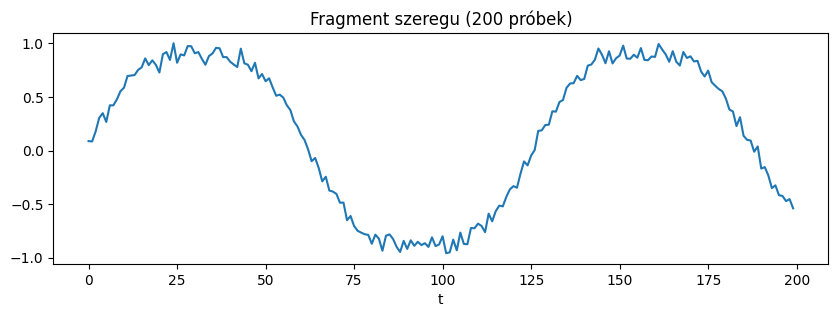

In [2]:
def generuj_szereg(n=2000):
    t = np.linspace(0, 100, n)
    y = np.sin(t) + 0.1*np.sin(3*t) + 0.05*np.random.randn(n)
    return y.astype(np.float32)

seria = generuj_szereg()
plt.figure(figsize=(10,3))
plt.plot(seria[:200])
plt.title('Fragment szeregu (200 próbek)'); plt.xlabel('t'); plt.show()

In [3]:
def zrob_okna(seria, okno=30):
    X, Y = [], []
    for i in range(len(seria)-okno):
        X.append(seria[i:i+okno]); Y.append(seria[i+okno])
    X = np.array(X, dtype=np.float32)[..., None]
    Y = np.array(Y, dtype=np.float32)[:, None]
    return X, Y

OKNO = 30
X, Y = zrob_okna(seria, OKNO)

n_tr = int(0.8*len(X))
Xtr = torch.tensor(X[:n_tr]).to(DEVICE); Ytr = torch.tensor(Y[:n_tr]).to(DEVICE)
Xte = torch.tensor(X[n_tr:]).to(DEVICE); Yte = torch.tensor(Y[n_tr:]).to(DEVICE)
print('Trening:', Xtr.shape, ' Test:', Xte.shape)

Trening: torch.Size([1576, 30, 1])  Test: torch.Size([394, 30, 1])


In [4]:
class ModelRNN(nn.Module):
    def __init__(self, hidden=32, typ='RNN'):
        super().__init__()
        rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ]
        self.rnn = rnn(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

In [5]:
def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    strata = nn.MSELoss()
    hist = []
    hist_tr=[]

    n = len(Xtr)
    for ep in range(epoki):
        model.train(); perm = torch.randperm(n)
        for i in range(0, n, batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = strata(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            epoch_loss=0.0

        model.eval()
        with torch.no_grad():
            hist.append(strata(model(Xte), Yte).item())
            hist_tr.append(strata(model(Xtr), Ytr).item())

    return hist, hist_tr

model = ModelRNN(hidden=32, typ='RNN')
hist, hist_tr = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30)
print(f'Strata test: {hist[0]:.4f} -> {hist[-1]:.4f}')
print(f'Strata treningowa: {hist_tr[0]:.4f} -> {hist_tr[-1]:.4f}')

Strata test: 0.0078 -> 0.0038
Strata treningowa: 0.0077 -> 0.0037


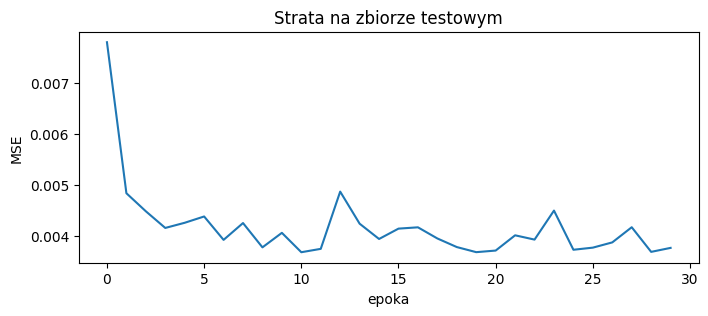

In [ ]:
plt.figure(figsize=(8,3))
plt.plot(hist)
plt.title('Strata na zbiorze testowym'); plt.xlabel('epoka'); plt.ylabel('MSE'); plt.show()

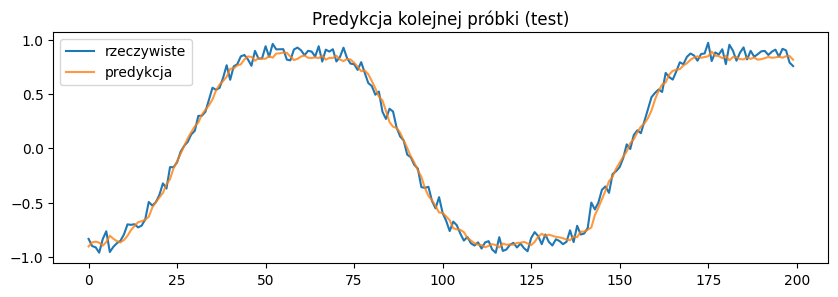

In [ ]:
model.eval()
with torch.no_grad():
    pred = model(Xte).cpu().numpy().ravel()
prawdziwe = Yte.cpu().numpy().ravel()

plt.figure(figsize=(10,3))
plt.plot(prawdziwe[:200], label='rzeczywiste')
plt.plot(pred[:200], label='predykcja', alpha=0.8)
plt.legend(); plt.title('Predykcja kolejnej próbki (test)'); plt.show()

In [ ]:
print('Typ komórki (hidden=32):')
for typ in ['RNN','LSTM','GRU']:
    h, _ = trenuj(ModelRNN(hidden=32, typ=typ), Xtr, Ytr, Xte, Yte, epoki=20)
    print(f'  {typ:5s} test MSE = {h[-1]:.4f}')

print('Liczba jednostek (GRU):')
for hs in [8, 32, 64]:
    h, _ = trenuj(ModelRNN(hidden=hs, typ='GRU'), Xtr, Ytr, Xte, Yte, epoki=20)
    print(f'  hidden={hs:3d} test MSE = {h[-1]:.4f}')

Typ komórki (hidden=32):
  RNN   test MSE = 0.0055
  LSTM  test MSE = 0.0036
  GRU   test MSE = 0.0035
Liczba jednostek (GRU):
  hidden=  8 test MSE = 0.0034
  hidden= 32 test MSE = 0.0038
  hidden= 64 test MSE = 0.0034


In [ ]:
print(f'Heurystyka MSE: {((Yte - Xte[:, -1])**2).mean().item():.5f}')

Heurystyka MSE: 0.00631


#EKSPERYMENT A
Hipoteza: Zwiększenie liczby jednostek (hidden) z 8 do 64 dla komórki GRU obniży testowe MSE, ponieważ model zyska większą pojemność do modelowania sygnału. Jednakże dla najwyższych wartości (np. 64) zysk może być mniejszy, a czas treningu znacząco wzrośnie.

Eksperyment A: Wpływ parametru hidden (GRU, OKNO=30)
Hidden= 8 | Parametry =   273 | MSE = 0.00380 ± 0.00004 | Czas = 1.2 s
Hidden=16 | Parametry =   929 | MSE = 0.00374 ± 0.00002 | Czas = 1.2 s
Hidden=32 | Parametry =  3393 | MSE = 0.00376 ± 0.00001 | Czas = 1.2 s
Hidden=64 | Parametry = 12929 | MSE = 0.00375 ± 0.00008 | Czas = 1.2 s


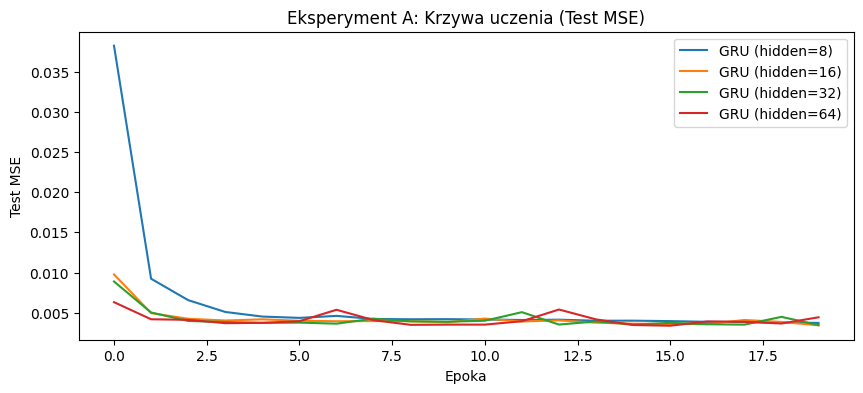

In [ ]:
import time

print("Eksperyment A: Wpływ parametru hidden (GRU, OKNO=30)")
plt.figure(figsize=(10, 4))

for hs in [8, 16, 32, 64]:
    wyniki, czasy = [], []
    krzywa_testowa = None

    for seed in [0, 1, 2]:
        torch.manual_seed(seed)
        model = ModelRNN(hidden=hs, typ='GRU')

        t0 = time.perf_counter()
        h, h_tr = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=20, lr=1e-2, batch=64)
        czasy.append(time.perf_counter() - t0)

        wyniki.append(np.mean(h[-5:]))

        if seed == 0:
            krzywa_testowa = h

    parametry = sum(p.numel() for p in model.parameters())
    print(f'Hidden={hs:2d} | Parametry = {parametry:5d} | '
          f'MSE = {np.mean(wyniki):.5f} ± {np.std(wyniki):.5f} | '
          f'Czas = {np.mean(czasy):.1f} s')

    plt.plot(krzywa_testowa, label=f'GRU (hidden={hs})')

plt.title('Eksperyment A: Krzywa uczenia (Test MSE)')
plt.xlabel('Epoka')
plt.ylabel('Test MSE')
plt.legend()
plt.show()

#EKSPERYMENT B
Hipoteza: Zwiększenie długości okna dostarczy modelowi GRU szerszy kontekst z przeszłości sygnału, co powinno ułatwić mu rozpoznanie fazy i kierunku zmian, a tym samym obniżyć błąd MSE. Jednak zbyt długie okno (np. 120 próbek) może pogorszyć wyniki ze względu na trudniejszy trening (wydłużony łańcuch BPTT i ryzyko zanikającego gradientu) oraz dłuższą epokę.

Eksperyment B: Wpływ długości okna (GRU, hidden=32)
Okno= 10 | Parametry =  3393 | MSE = 0.00414 ± 0.00019 | Czas = 1.2 s
Okno= 30 | Parametry =  3393 | MSE = 0.00376 ± 0.00001 | Czas = 1.2 s
Okno= 60 | Parametry =  3393 | MSE = 0.00343 ± 0.00021 | Czas = 1.2 s
Okno=120 | Parametry =  3393 | MSE = 0.00344 ± 0.00019 | Czas = 1.2 s


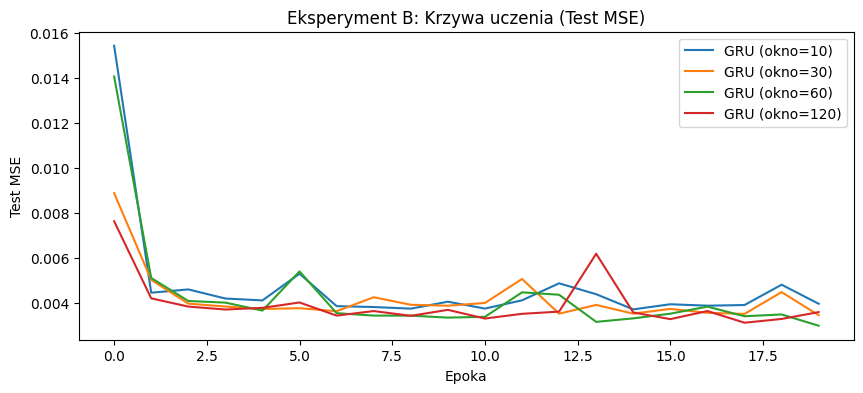

In [ ]:
print("Eksperyment B: Wpływ długości okna (GRU, hidden=32)")
plt.figure(figsize=(10, 4))

for okno in [10, 30, 60, 120]:
    wyniki, czasy = [], []
    krzywa_testowa = None

    X_nowe, Y_nowe = zrob_okna(seria, okno)
    n_tr = int(0.8*len(X_nowe))
    Xtr_nowe = torch.tensor(X_nowe[:n_tr]).to(DEVICE)
    Ytr_nowe = torch.tensor(Y_nowe[:n_tr]).to(DEVICE)
    Xte_nowe = torch.tensor(X_nowe[n_tr:]).to(DEVICE)
    Yte_nowe = torch.tensor(Y_nowe[n_tr:]).to(DEVICE)

    for seed in [0, 1, 2]:
        torch.manual_seed(seed)
        model = ModelRNN(hidden=32, typ='GRU')

        t0 = time.perf_counter()
        h, h_tr = trenuj(model, Xtr_nowe, Ytr_nowe, Xte_nowe, Yte_nowe, epoki=20, lr=1e-2, batch=64)
        czasy.append(time.perf_counter() - t0)

        wyniki.append(np.mean(h[-5:]))

        if seed == 0:
            krzywa_testowa = h

    parametry = sum(p.numel() for p in model.parameters())
    print(f'Okno={okno:3d} | Parametry = {parametry:5d} | '
          f'MSE = {np.mean(wyniki):.5f} ± {np.std(wyniki):.5f} | '
          f'Czas = {np.mean(czasy):.1f} s')

    plt.plot(krzywa_testowa, label=f'GRU (okno={okno})')

plt.title('Eksperyment B: Krzywa uczenia (Test MSE)')
plt.xlabel('Epoka')
plt.ylabel('Test MSE')
plt.legend()
plt.show()

#EKSPERYMENT C
Hipoteza: Dla krótkiego okna (10 próbek) różnice między RNN, LSTM i GRU są niewielkie, gdyż gradient łatwo przepływa w BPTT. Przy długim oknie (120 próbek) zwykły RNN radzi sobie gorzej przez zanikający gradient, podczas gdy LSTM i GRU zachowują stabilność i niższe MSE dzięki bramkom oraz kilkukrotnie większej liczbie parametrów przy tym samym hidden=32.

Eksperyment C: Porównanie RNN, LSTM, GRU (okno=10 i okno=120, hidden=32)

--- Wyniki dla OKNO = 10 ---
Typ=RNN  | Parametry =  1153 | MSE = 0.00417 ± 0.00025 | Czas = 1.1 s
Typ=LSTM | Parametry =  4513 | MSE = 0.00415 ± 0.00011 | Czas = 1.2 s
Typ=GRU  | Parametry =  3393 | MSE = 0.00414 ± 0.00019 | Czas = 1.2 s

--- Wyniki dla OKNO = 120 ---
Typ=RNN  | Parametry =  1153 | MSE = 0.00400 ± 0.00001 | Czas = 1.1 s
Typ=LSTM | Parametry =  4513 | MSE = 0.00375 ± 0.00013 | Czas = 1.3 s
Typ=GRU  | Parametry =  3393 | MSE = 0.00344 ± 0.00019 | Czas = 1.2 s


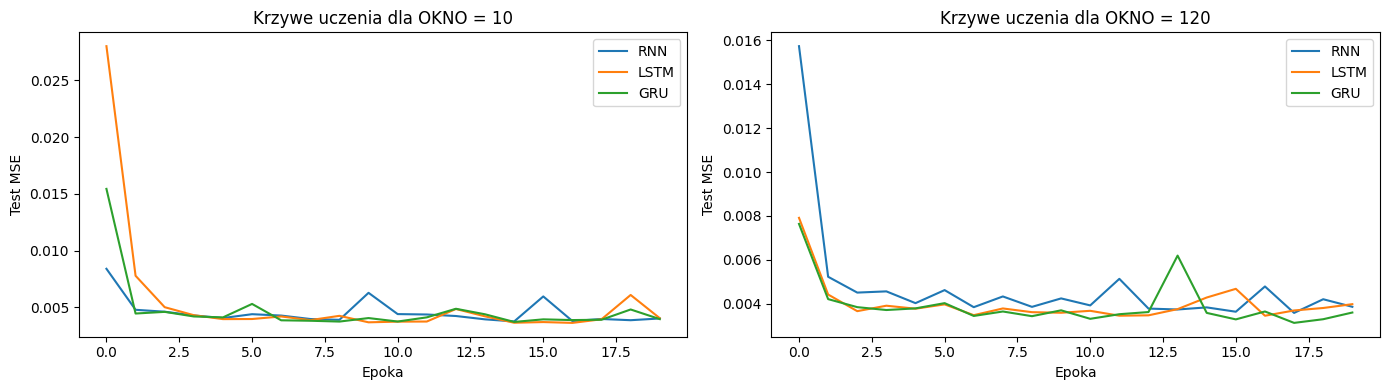

In [ ]:
print("Eksperyment C: Porównanie RNN, LSTM, GRU (okno=10 i okno=120, hidden=32)")

okna_do_testu = [10, 120]
typy_komorek = ['RNN', 'LSTM', 'GRU']

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for idx_okna, okno in enumerate(okna_do_testu):
    print(f"\n--- Wyniki dla OKNO = {okno} ---")

    X_nowe, Y_nowe = zrob_okna(seria, okno)
    n_tr = int(0.8*len(X_nowe))
    Xtr_nowe = torch.tensor(X_nowe[:n_tr]).to(DEVICE)
    Ytr_nowe = torch.tensor(Y_nowe[:n_tr]).to(DEVICE)
    Xte_nowe = torch.tensor(X_nowe[n_tr:]).to(DEVICE)
    Yte_nowe = torch.tensor(Y_nowe[n_tr:]).to(DEVICE)

    for typ in typy_komorek:
        wyniki, czasy = [], []
        krzywa_testowa = None

        for seed in [0, 1, 2]:
            torch.manual_seed(seed)
            model = ModelRNN(hidden=32, typ=typ)

            t0 = time.perf_counter()
            h, h_tr = trenuj(model, Xtr_nowe, Ytr_nowe, Xte_nowe, Yte_nowe, epoki=20, lr=1e-2, batch=64)
            czasy.append(time.perf_counter() - t0)

            wyniki.append(np.mean(h[-5:]))

            if seed == 0:
                krzywa_testowa = h

        parametry = sum(p.numel() for p in model.parameters())
        print(f'Typ={typ:4s} | Parametry = {parametry:5d} | '
              f'MSE = {np.mean(wyniki):.5f} ± {np.std(wyniki):.5f} | '
              f'Czas = {np.mean(czasy):.1f} s')

        axes[idx_okna].plot(krzywa_testowa, label=f'{typ}')

    axes[idx_okna].set_title(f'Krzywe uczenia dla OKNO = {okno}')
    axes[idx_okna].set_xlabel('Epoka')
    axes[idx_okna].set_ylabel('Test MSE')
    axes[idx_okna].legend()

plt.tight_layout()
plt.show()

Wykresy


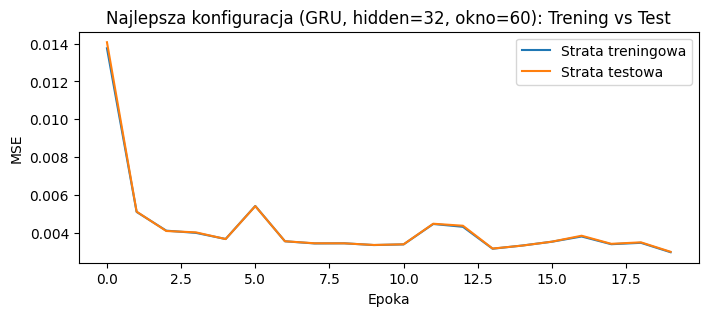

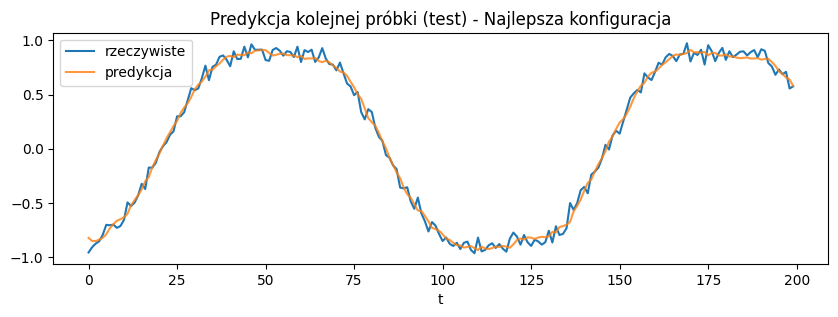

In [6]:
X_b, Y_b = zrob_okna(seria, 60)
n_tr = int(0.8 * len(X_b))
Xtr_b = torch.tensor(X_b[:n_tr]).to(DEVICE)
Ytr_b = torch.tensor(Y_b[:n_tr]).to(DEVICE)
Xte_b = torch.tensor(X_b[n_tr:]).to(DEVICE)
Yte_b = torch.tensor(Y_b[n_tr:]).to(DEVICE)

torch.manual_seed(0)
model_b = ModelRNN(hidden=32, typ='GRU')
h_test, h_train = trenuj(
    model_b, Xtr_b, Ytr_b, Xte_b, Yte_b, epoki=20, lr=1e-2, batch=64
)

plt.figure(figsize=(8, 3))
plt.plot(h_train, label='Strata treningowa')
plt.plot(h_test, label='Strata testowa')
plt.title('Najlepsza konfiguracja (GRU, hidden=32, okno=60): Trening vs Test')
plt.xlabel('Epoka')
plt.ylabel('MSE')
plt.legend()
plt.show()

model_b.eval()
with torch.no_grad():
  pred_b = model_b(Xte_b).cpu().numpy().ravel()
prawdziwe_b = Yte_b.cpu().numpy().ravel()

plt.figure(figsize=(10, 3))
plt.plot(prawdziwe_b[:200], label='rzeczywiste')
plt.plot(pred_b[:200], label='predykcja', alpha=0.8)
plt.title('Predykcja kolejnej próbki (test) - Najlepsza konfiguracja')
plt.xlabel('t')
plt.legend()
plt.show()